In [1]:
import torch
import torch.nn as nn
import pandas as pd

print("PyTorch version:", torch.__version__)
print("Setup successful!")

PyTorch version: 2.14.1+cpu
Setup successful!


In [2]:
class Standard_CNN(nn.Module):
    def __init__(self):#modified vgg16+lenet5
        super().__init__()
        self.Conv1 = nn.Conv2d(1,6,kernel_size=3,stride=1,padding=1)#maxpooling doesnt change the cin or cout.. only downsample the picture
        self.batch_norm1 = nn.BatchNorm2d(6)
        self.Conv2 = nn.Conv2d(6,16,kernel_size=3,stride=1,padding=1)
        self.batch_norm2 = nn.BatchNorm2d(16)
        self.fc1    = nn.Linear(16*4*4,120)
        self.fc2    = nn.Linear(120,84)
        self.fc3    = nn.Linear(84,10)
    def forward(self,x):
        x = torch.relu(self.batch_norm1(self.Conv1(x)))
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = torch.relu(self.batch_norm2(self.Conv2(x)))
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = x.view(-1,16*4*4)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [3]:
class DepthWise_Separable_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1_depth = nn.Conv2d(1,1,kernel_size=3,padding=1,groups=1)
        self.batch_norm_1_1 = nn.BatchNorm2d(1)
        self.conv1_point = nn.Conv2d(1,6,kernel_size=1,groups=1)
        self.batch_norm_1_2 = nn.BatchNorm2d(6)
        self.conv2_depth = nn.Conv2d(6,6,kernel_size=3,padding=1,groups=6)
        self.batch_norm_2_1 = nn.BatchNorm2d(6)
        self.conv2_point = nn.Conv2d(6,16,kernel_size=1,groups=1)
        self.batch_norm_2_2 = nn.BatchNorm2d(16)
        self.fc1    = nn.Linear(16*4*4,120)
        self.fc2    = nn.Linear(120,84)
        self.fc3    = nn.Linear(84,10)

    def forward(self,x):
        x = self.conv1_depth(x)
        x = self.batch_norm_1_1(x)
        x = torch.relu(x)
        x = self.conv1_point(x)
        x = self.batch_norm_1_2(x)
        x = torch.relu(x)
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = self.conv2_depth(x)
        x = self.batch_norm_2_1(x)
        x = torch.relu(x)
        x = self.conv2_point(x)
        x = self.batch_norm_2_2(x)
        x = torch.relu(x)
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = x.view(-1,16*4*4)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [4]:
model_A = Standard_CNN()
model_B = DepthWise_Separable_CNN()

print("Both CNN models created successfully!")

Both CNN models created successfully!


In [5]:
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


params_A = count_parameters(model_A)
params_B = count_parameters(model_B)

print("Model A trainable parameters:", params_A)
print("Model B trainable parameters:", params_B)

if params_B <= 100000:
    print("Model B satisfies the 100,000 parameter limit.")
else:
    print("Model B exceeds the parameter limit!")

Model A trainable parameters: 42838
Model B trainable parameters: 42106
Model B satisfies the 100,000 parameter limit.


In [6]:
def estimated_weight_size_kb(model):
    total_bytes = sum(
        p.numel() * p.element_size()
        for p in model.parameters()
    )
    return total_bytes / 1024


size_A = estimated_weight_size_kb(model_A)
size_B = estimated_weight_size_kb(model_B)

print(f"Model A weight size: {size_A:.2f} KB")
print(f"Model B weight size: {size_B:.2f} KB")

Model A weight size: 167.34 KB
Model B weight size: 164.48 KB


In [7]:
comparison = pd.DataFrame({
    "Model": [
        "Standard CNN",
        "Depthwise Separable CNN"
    ],
    "Trainable Parameters": [
        params_A,
        params_B
    ],
    "Estimated Weight Size (KB)": [
        round(size_A, 2),
        round(size_B, 2)
    ]
})

display(comparison)

,Model,Trainable Parameters,Estimated Weight Size (KB)
0,Standard CNN,42838,167.34
1,Depthwise Separable CNN,42106,164.48


In [8]:
reduction = (params_A - params_B) / params_A * 100

print(f"Parameter reduction: {reduction:.2f}%")

Parameter reduction: 1.71%


# Model B: Classification Performance Evaluation

This section evaluates the custom Depthwise Separable CNN
(Model B) using the Fashion-MNIST dataset.

The evaluation includes:
- Classification accuracy
- Precision, recall, and F1-score
- Confusion matrix
- Per-class performance analysis

The model is trained for 20 epochs using a stratified
70/15/15 training, validation, and test split.

In [9]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset, ConcatDataset
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


Using device: cpu


In [10]:
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor()
])

data_root = "../FashionMNIST"

original_train = torchvision.datasets.FashionMNIST(
    root=data_root, train=True, download=True,
    transform=transform
)

original_test = torchvision.datasets.FashionMNIST(
    root=data_root, train=False, download=True,
    transform=transform
)

all_data = ConcatDataset([original_train, original_test])

all_labels = torch.cat([
    original_train.targets,
    original_test.targets
])

print("Total images:", len(all_data))


100.0%
100.0%
100.0%
100.0%

Total images: 70000


In [11]:
split_generator = torch.Generator().manual_seed(42)

train_indices = []
val_indices = []
test_indices = []

for class_id in range(10):

    indices = torch.where(all_labels == class_id)[0]

    shuffled = torch.randperm(
        len(indices),
        generator=split_generator
    )

    indices = indices[shuffled]

    train_end = int(0.70 * len(indices))
    val_end = train_end + int(0.15 * len(indices))

    train_indices.extend(indices[:train_end].tolist())
    val_indices.extend(indices[train_end:val_end].tolist())
    test_indices.extend(indices[val_end:].tolist())

train_dataset = Subset(all_data, train_indices)
val_dataset = Subset(all_data, val_indices)
test_dataset = Subset(all_data, test_indices)

trainloader = DataLoader(
    train_dataset, batch_size=50, shuffle=True
)

valloader = DataLoader(
    val_dataset, batch_size=50, shuffle=False
)

testloader = DataLoader(
    test_dataset, batch_size=50, shuffle=False
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 49000
Validation: 10500
Testing: 10500


In [12]:
torch.manual_seed(42)

trained_model_B = DepthWise_Separable_CNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    trained_model_B.parameters(),
    lr=0.001
)

print("Model B initialized successfully!")


Model B initialized successfully!


In [13]:
epochs = 20

train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):

    # Training phase
    trained_model_B.train()
    running_train_loss = 0.0

    for images, labels in trainloader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = trained_model_B(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    avg_train_loss = running_train_loss / len(train_dataset)
    train_losses.append(avg_train_loss)

    # Validation phase
    trained_model_B.eval()

    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in valloader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = trained_model_B(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_val_loss = running_val_loss / len(val_dataset)
    val_accuracy = 100 * correct / total

    val_losses.append(avg_val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

print("Model B training completed!")

Epoch 1/20 | Train Loss: 0.6236 | Val Loss: 0.5255 | Val Acc: 80.10%
Epoch 2/20 | Train Loss: 0.4333 | Val Loss: 0.3997 | Val Acc: 85.30%
Epoch 3/20 | Train Loss: 0.3874 | Val Loss: 0.4057 | Val Acc: 85.00%
Epoch 4/20 | Train Loss: 0.3601 | Val Loss: 0.4137 | Val Acc: 84.61%
Epoch 5/20 | Train Loss: 0.3425 | Val Loss: 0.3548 | Val Acc: 86.96%
Epoch 6/20 | Train Loss: 0.3241 | Val Loss: 0.3433 | Val Acc: 87.28%
Epoch 7/20 | Train Loss: 0.3095 | Val Loss: 0.3467 | Val Acc: 87.47%
Epoch 8/20 | Train Loss: 0.2992 | Val Loss: 0.3302 | Val Acc: 87.90%
Epoch 9/20 | Train Loss: 0.2893 | Val Loss: 0.3265 | Val Acc: 87.66%
Epoch 10/20 | Train Loss: 0.2818 | Val Loss: 0.3198 | Val Acc: 88.56%
Epoch 11/20 | Train Loss: 0.2728 | Val Loss: 0.3231 | Val Acc: 88.33%
Epoch 12/20 | Train Loss: 0.2638 | Val Loss: 0.3154 | Val Acc: 88.43%
Epoch 13/20 | Train Loss: 0.2596 | Val Loss: 0.3019 | Val Acc: 88.87%
Epoch 14/20 | Train Loss: 0.2510 | Val Loss: 0.2994 | Val Acc: 88.78%
Epoch 15/20 | Train Loss: 0.2

In [14]:
Path("checkpoints").mkdir(exist_ok=True)

checkpoint_path = "checkpoints/model_B_20epochs.pth"

torch.save(
    trained_model_B.state_dict(),
    checkpoint_path
)

print("Saved model to:", checkpoint_path)

Saved model to: checkpoints/model_B_20epochs.pth


In [15]:
trained_model_B = DepthWise_Separable_CNN().to(device)

trained_model_B.load_state_dict(
    torch.load(
        "checkpoints/model_B_20epochs.pth",
        map_location=device,
        weights_only=True
    )
)

trained_model_B.eval()

DepthWise_Separable_CNN(
  (conv1_depth): Conv2d(1, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batch_norm_1_1): BatchNorm2d(1, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv1_point): Conv2d(1, 6, kernel_size=(1, 1), stride=(1, 1))
  (batch_norm_1_2): BatchNorm2d(6, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2_depth): Conv2d(6, 6, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=6)
  (batch_norm_2_1): BatchNorm2d(6, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2_point): Conv2d(6, 16, kernel_size=(1, 1), stride=(1, 1))
  (batch_norm_2_2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc1): Linear(in_features=256, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

## Model B: Test Set Evaluation

The trained Model B is evaluated on the held-out
10,500-image test set. No training is performed
during this stage.

In [16]:
trained_model_B.eval()

all_predictions = []
all_true_labels = []

with torch.no_grad():

    for images, labels in testloader:

        images = images.to(device)

        outputs = trained_model_B(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_true_labels.extend(
            labels.numpy()
        )

print("Total predictions:", len(all_predictions))
print("Total true labels:", len(all_true_labels))

Total predictions: 10500
Total true labels: 10500


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy_B = accuracy_score(
    all_true_labels, all_predictions
)

precision_B = precision_score(
    all_true_labels, all_predictions,
    average="macro", zero_division=0
)

recall_B = recall_score(
    all_true_labels, all_predictions,
    average="macro", zero_division=0
)

f1_B = f1_score(
    all_true_labels, all_predictions,
    average="macro", zero_division=0
)

print(f"Accuracy:  {accuracy_B * 100:.2f}%")
print(f"Precision: {precision_B * 100:.2f}%")
print(f"Recall:    {recall_B * 100:.2f}%")
print(f"F1-score:  {f1_B * 100:.2f}%")


Accuracy:  88.62%
Precision: 88.59%
Recall:    88.62%
F1-score:  88.45%


In [18]:
class_names = original_train.classes

print(
    classification_report(
        all_true_labels,
        all_predictions,
        labels=list(range(10)),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.81      0.83      1050
     Trouser       0.95      0.99      0.97      1050
    Pullover       0.74      0.89      0.81      1050
       Dress       0.87      0.90      0.89      1050
        Coat       0.83      0.78      0.80      1050
      Sandal       0.97      0.97      0.97      1050
       Shirt       0.75      0.62      0.68      1050
     Sneaker       0.96      0.96      0.96      1050
         Bag       0.97      0.98      0.98      1050
  Ankle boot       0.96      0.97      0.97      1050

    accuracy                           0.89     10500
   macro avg       0.89      0.89      0.88     10500
weighted avg       0.89      0.89      0.88     10500



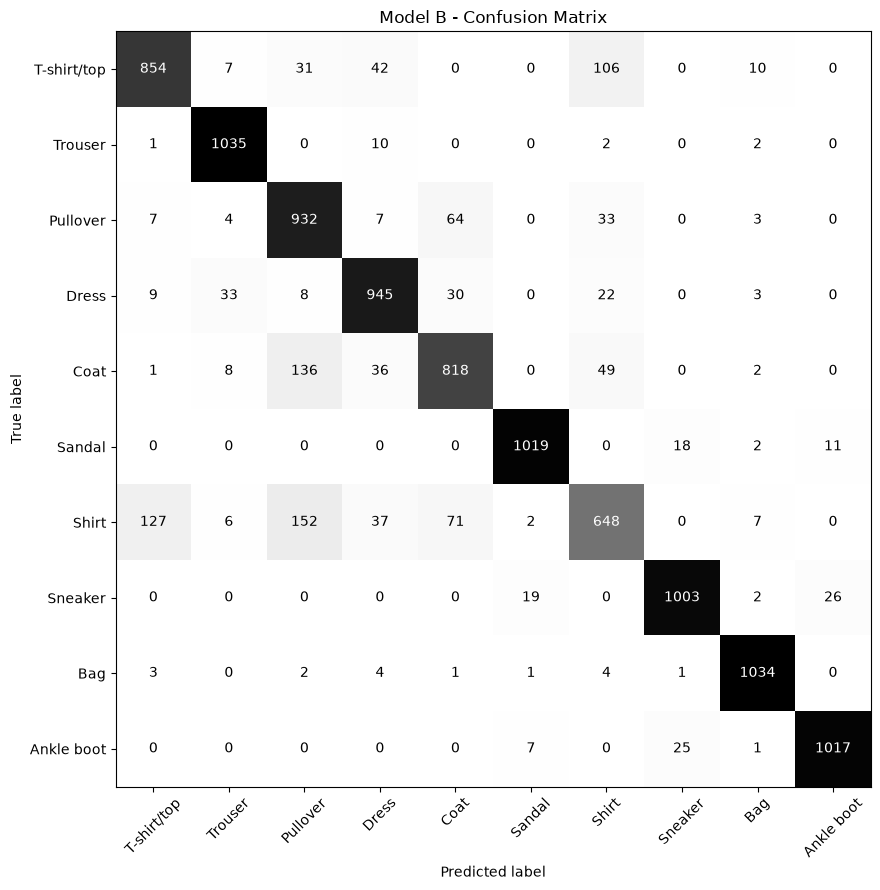

In [19]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Greys",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Model B - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "model_B_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


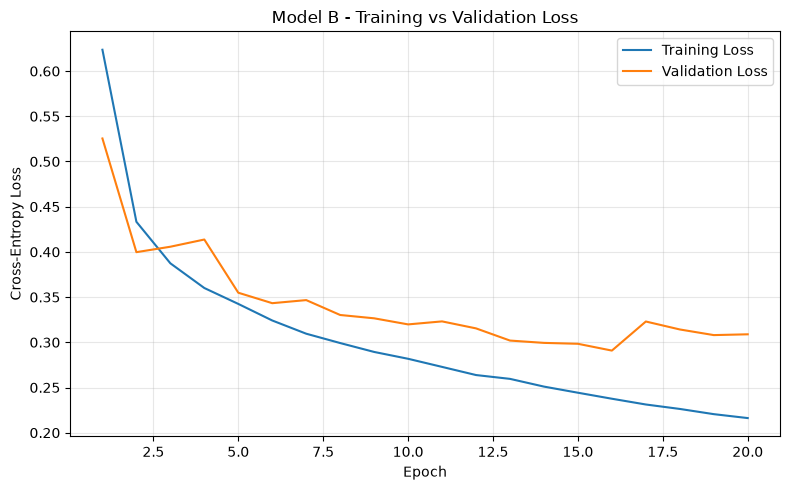

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 21),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, 21),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Model B - Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "model_B_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [22]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

results_B = pd.DataFrame({
    "Model": ["Depthwise Separable CNN"],
    "Accuracy (%)": [
        accuracy_score(all_true_labels, all_predictions) * 100
    ],
    "Precision (%)": [
        precision_score(all_true_labels, all_predictions, average="macro") * 100
    ],
    "Recall (%)": [
        recall_score(all_true_labels, all_predictions, average="macro") * 100
    ],
    "F1 (%)": [
        f1_score(all_true_labels, all_predictions, average="macro") * 100
    ]
})

display(results_B.round(2))

results_B.to_csv(
    "model_B_evaluation_results.csv",
    index=False
)

,Model,Accuracy (%),Precision (%),Recall (%),F1 (%)
0,Depthwise Separable CNN,88.62,88.59,88.62,88.45


### Model B Performance Discussion

The training loss decreased consistently across the 20 epochs,
indicating successful learning. The validation loss initially
decreased before stabilizing after approximately 10-12 epochs.
A small increase in validation loss toward the final epochs
suggests mild overfitting.

The final test performance was evaluated using accuracy,
macro-averaged precision, recall, F1-score, and a confusion
matrix.

The confusion matrix was used to identify the classes that
were most frequently misclassified.